In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
from scipy.optimize import least_squares
from scipy.special import modstruve
from scipy.special import kv
from scipy.io import loadmat
from scipy.stats import norm
from scipy.stats import t

In [2]:
''' Helper function to load the data we care about. '''
def load_mat_file(filename, numberofpatterns):
    # Load the MATLAB file.
    data = sio.loadmat(filename, squeeze_me=True, struct_as_record=False)
    results = data['results']
    results = results.flatten()
    
    # The main data we care about, for now, are...
    #         w_slit: the slit width, read from the micrometer.
    #   w_excitation: the excitation width, extracted from the image. This is correlated with 'w_slit'.
    #              y: the center-to-center distance between the slit and a pattern. 1x4 array.
    # pattern_signal: the signal measured from the pattern. 1x4 array.
    #  pattern_error: the error in 'pattern_signal'. 1x4 array.
    
    # Preallocate arrays.
    w_slit         = np.zeros((len(results), 1))
    w_excitation   = np.zeros((len(results), 1))
    y              = np.zeros((len(results), numberofpatterns))
    pattern_signal = np.zeros((len(results), numberofpatterns))
    pattern_error  = np.zeros((len(results), numberofpatterns))
    for i, entry in enumerate(results):
        w_slit[i] = entry.w_nominal
        w_excitation[i] = entry.w_measured
        y[i,:] = entry.y_measured
        pattern_signal[i,:] = np.array(entry.pattern_signal)
        pattern_error[i,:] = np.array(entry.pattern_error)
    
    return w_slit, w_excitation, y, pattern_signal, pattern_error

In [3]:
# Now load all the data and concatenate.
w_slit_1, w_excitation_1, y_1, pattern_signal_1, pattern_error_1 = load_mat_file('YAGYb_PC-27_07-07-2025_Variable_w-values_results_10-19-2026.mat', 11)
w_slit_2, w_excitation_2, y_2, pattern_signal_2, pattern_error_2 = load_mat_file('YAGYb_PC-27_07-07-2025_Variable_y-values_results_10-19-2026.mat', 11)

w_slit         = np.concatenate((w_slit_1, w_slit_2), axis=0)
w_excitation   = np.concatenate((w_excitation_1, w_excitation_2), axis=0)
y              = np.concatenate((y_1, y_2), axis=0)
pattern_signal = np.concatenate((pattern_signal_1, pattern_signal_2), axis=0)
pattern_error  = np.concatenate((pattern_error_1, pattern_error_2), axis=0)

# Convert w to a in units of microns (to be discussed).
a_slit = w_slit/2 * (25.4*1e3)
a_excitation = w_excitation/2 * (25.4*1e3)

# Convert y to units of microns.
y_in = y
y_µm = y_in * (25.4*1e3)

# Normalize the data.
pattern_signal_normalized = pattern_signal/np.max(pattern_signal)
pattern_error_normalized = pattern_error/np.max(pattern_signal)

In [4]:
''' Average the data '''
average_pattern_signal = np.sum(pattern_signal_normalized/(pattern_error_normalized**2), axis=1) / np.sum(1/(pattern_error_normalized**2), axis=1)
average_pattern_error  = np.sqrt(1/np.sum(1/(pattern_error_normalized**2), axis=1))
average_y_µm = np.mean(y_µm, axis=1)

In [5]:
''' Functions that define our model (see text below for details) '''
# First part of the model.
def func(y, a, λ):
    b = (y-a)/λ
    c = (y+a)/λ
    return c*modstruve(-1,c)*kv(0,c) + c*modstruve(0,c)*kv(1,c) - b*modstruve(-1,b)*kv(0,b) - b*modstruve(0,b)*kv(1,b)

# Define the full model function.
def model_func(params, y, a):
    λ = params[0]
    C = params[1]
    return C*func(y, a, λ)

# Define the residuals function for multiple energies.
def residuals(params, I, y, a):
    return I - model_func(params, y, a)

''' Suggested by ChatGPT '''
def model_confidence_band(params, covariance, dof, y, a, confidence_level=0.95):
    # Evaluate the fitted curve.
    model_A = np.asarray(model_func(params, y, a)).ravel()

    # Calculate the gradient with respect to λ and C.
    G = np.empty((model_A.size, 2))

    # Numerical derivative with respect to λ.
    h = np.cbrt(np.finfo(float).eps)*max(abs(params[0]), 1.0)
    p_plus, p_minus = params.copy(), params.copy()
    p_plus[0] += h
    p_minus[0] -= h

    G[:,0] = ((model_func(p_plus, y, a) -
               model_func(p_minus, y, a))/(2*h)).ravel()

    # Analytical derivative with respect to C.
    G[:,1] = np.asarray(func(y, a, params[0])).ravel()

    # Propagate parameter covariance to the fitted curve.
    variance = np.einsum('ij,jk,ik->i', G, covariance, G)
    sigma = np.sqrt(np.maximum(variance, 0))

    # Calculate pointwise 95% confidence limits.
    t_crit = t.ppf(1-(1-confidence_level)/2, dof)

    model_A_lower = model_A - t_crit*sigma
    model_A_upper = model_A + t_crit*sigma

    return model_A, model_A_lower, model_A_upper

In [6]:
''' Fit the data. '''
A = np.ndarray.flatten(pattern_signal_normalized)
y_collapsed = np.ndarray.flatten(y_µm)
a_collapsed = np.ndarray.flatten(np.tile(np.squeeze(a_excitation), (11,1)).transpose())

# Initial guesses.
wvl = 0.550 # In microns.
k = 1e-6
λ_init = wvl/(4*np.pi*k) # Initial guess is attenuation length from Beer-Lambert law.
C_init = 1.0
initial_params = np.hstack([λ_init, C_init])

# Check to make sure the residuals are defined.
test = residuals(initial_params, A, y_collapsed, a_collapsed)
if np.isnan(test).any():
    print('Some of the residuals are nan!')
    indices = ~np.isnan(test)
    A = A[indices]
    y_collapsed = y_collapsed[indices]
    a_collapsed = a_collapsed[indices]

# Perform the fit.
result = least_squares(residuals, initial_params, args=(A, y_collapsed, a_collapsed))

# Extract fitted parameters.
parameter_estimates = result.x

# Calculate the Jacobian matrix and the cost.
# J = result.jac # Jacobian matrix at the solution.
# cost = result.cost # Sum of squared residuals at the solution.
# degrees_of_freedom = len(A) - 2 # Number of data points minus number of parameters.

# Estimate the variance of the residuals.
# residual_variance = cost/degrees_of_freedom

# Calculate the covariance matrix for the parameters.
# covariance_matrix = residual_variance*np.linalg.inv(J.T @ J)

# Calculate the standard errors (square roots of the diagonal of the covariance matrix).
# parameter_errors = np.sqrt(np.diag(covariance_matrix))

''' Correction from ChatGPT '''
J = result.jac
cost = result.cost
dof = result.fun.size - result.x.size

residual_variance = 2*cost/dof
covariance_matrix = residual_variance*np.linalg.inv(J.T @ J)

parameter_errors = np.sqrt(np.diag(covariance_matrix))

C:\Users\simop\AppData\Local\Temp/ipykernel_21416/1949141061.py:6: RuntimeWarning: invalid value encountered in multiply
  return c*modstruve(-1,c)*kv(0,c) + c*modstruve(0,c)*kv(1,c) - b*modstruve(-1,b)*kv(0,b) - b*modstruve(0,b)*kv(1,b)


In [7]:
# confidence_level = 0.95
# z = norm.ppf(1-(1-confidence_level)/2)  # 1.96 for 95% confidence.

# Calculate upper and lower bounds for each parameter.
# result_upper = parameter_estimates + z*parameter_errors
# result_lower = parameter_estimates - z*parameter_errors

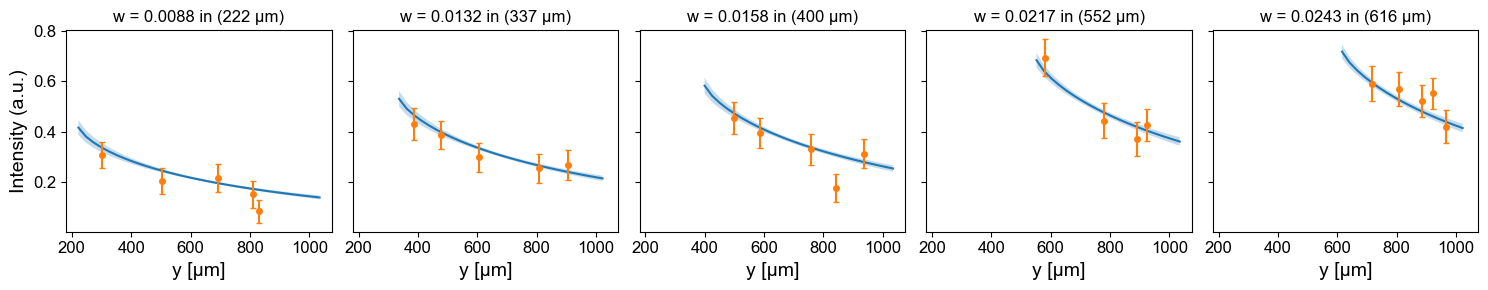

In [8]:
# Set font globally.
plt.rcParams['pdf.fonttype'] = 42  # Type 42 (TrueType), required for Adobe Illustrator.
plt.rcParams['ps.fonttype'] = 42   # Ensures fonts are saved as TrueType in EPS.
plt.rcParams['font.family'] = 'Arial'
params = {'mathtext.default': 'regular' }          
plt.rcParams.update(params)

# Colors corresponding to different patterns.
# colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
# colors = plt.get_cmap('viridis', n_patterns)(np.arange(n_patterns))

''' We are going to break up the dataset into
    the original two segments: one that showcases
    a- and y-dependence, and one that showcases
    a-dependence over a fine step size. '''
# First: a- and y-depdendent data.
a_nominal = np.array([0.005, 0.008, 0.010, 0.013, 0.015])/2 # Same as the experimental points.
a_fit = np.array([0.0175, 0.0265, 0.0315, 0.0435, 0.0485])/2 # Rough approximation of a slightly variable slit width.
fig, axes = plt.subplots(1, len(a_fit), figsize=(len(a_fit)*3, 3), sharex=True, sharey=True)
# Loop.
a_index = 0
for ax, current_a_fit in zip(axes, a_fit):
    # Plot the model fit.
    # We add 1e-6 to the left edge of the y-range. This is because the model diverges when y <= a.
    y_fit = np.arange(current_a_fit+1e-6, 0.040+0.001, 0.001) * (25.4*1e3)
    model_A, model_A_lower, model_A_upper = model_confidence_band(
        parameter_estimates,
        covariance_matrix,
        dof,
        y_fit,
        current_a_fit*(25.4*1e3)
    )
    ax.plot(y_fit, model_A)
    ax.fill_between(y_fit, model_A_upper, model_A_lower, alpha=0.25)
    
    # Plot the experimental data.
    current_a_nominal = a_nominal[np.where(current_a_fit == a_fit)][0]
    indices = np.where(a_slit == current_a_nominal*(25.4*1e3))
    ax.errorbar(average_y_µm[indices[0]], average_pattern_signal[indices[0]],
                yerr=average_pattern_error[indices[0]],
                fmt='o',
                ms=4,
                capsize=2)
    
    # Dress up the subplots.
    ax.set_xlabel('y [µm]', fontsize=14)
    if a_index == 0:
        ax.set_ylabel('Intensity (a.u.)', fontsize=14)
    ax.tick_params(axis='x', labelsize=12)
    ax.tick_params(axis='y', labelsize=12)
    ax.set_title('w = {:.4f} in ({:.0f} µm)'.format(current_a_fit, current_a_fit*(25.4*1e3)))
    a_index += 1

plt.tight_layout()
plt.show()

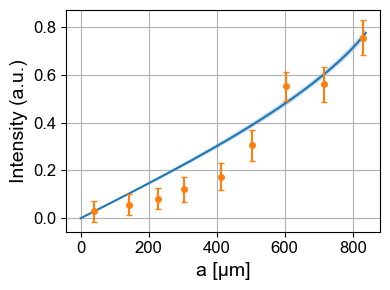

In [9]:
# Set font globally.
plt.rcParams['pdf.fonttype'] = 42  # Type 42 (TrueType), required for Adobe Illustrator.
plt.rcParams['ps.fonttype'] = 42   # Ensures fonts are saved as TrueType in EPS.
plt.rcParams['font.family'] = 'Arial'
params = {'mathtext.default': 'regular' }          
plt.rcParams.update(params)

# Colors corresponding to different patterns.
# colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
# colors = plt.get_cmap('viridis', n_patterns)(np.arange(n_patterns))

''' We are going to break up the dataset into
    the original two segments: one that showcases
    a- and y-dependence, and one that showcases
    a-dependence over a fine step size. '''
# Second: fine a-depdendent data.
# Get the average y-positions of the patterns (it was fixed during the experiments).
fig, ax = plt.subplots(1, 1, figsize=(4, 3), sharex=True, sharey=True)
# Loop.
# Plot the model fit.
# Get the average y-position of the current pattern.
y_fit = np.mean(np.squeeze(y_µm[0:9]))
# We add 1e-6 to the right edge of the y-range. This is because the model diverges when y <= a.
a_fit = np.arange(0, 0.04+0.001, 0.001) * (25.4*1e3)
model_A, model_A_lower, model_A_upper = model_confidence_band(
    parameter_estimates,
    covariance_matrix,
    dof,
    y_fit,
    a_fit
)
ax.plot(a_fit, model_A)
ax.fill_between(a_fit, model_A_upper, model_A_lower, alpha=0.25)
# Plot the experimental data.
# The first dataset ends at index 9 (remember Python adds 1 to a colon-separated range).
ax.errorbar(a_excitation[0:9], average_pattern_signal[0:9],
            yerr=average_pattern_error[0:9],
            fmt='o',
            ms=4,
            capsize=2)

# Dress up the subplots.
ax.set_xlabel('a [µm]', fontsize=14)
ax.set_ylabel('Intensity (a.u.)', fontsize=14)
ax.tick_params(axis='x', labelsize=12)
ax.tick_params(axis='y', labelsize=12)
ax.grid()

plt.tight_layout()
plt.show()

meta NOT subset; don't know how to subset; dropped


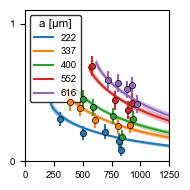

In [10]:
''' PLOT FOR THESIS. '''
# Set font globally.
plt.rcParams['pdf.fonttype'] = 42  # Type 42 (TrueType), required for Adobe Illustrator.
plt.rcParams['ps.fonttype'] = 42   # Ensures fonts are saved as TrueType in EPS.
plt.rcParams['font.family'] = 'Arial'
params = {'mathtext.default': 'regular' }          
plt.rcParams.update(params)

# Colors corresponding to different slit widths.
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown']

# First: a- and y-depdendent data.
a_nominal = np.array([0.005, 0.008, 0.010, 0.013, 0.015])/2 # Same as the experimental points.
a_fit = np.array([0.0175, 0.0265, 0.0315, 0.0435, 0.0485])/2 # Rough approximation of a slightly variable slit width.
fig, ax = plt.subplots(1, 1, figsize=(2, 2), sharex=True, sharey=True)
# Loop.
# Just plot data for pattern 1. That is the one with the fewest defects.
for i, current_a_fit in enumerate(a_fit):
    # Plot the model fit.
    # We add 1e-6 to the left edge of the y-range. This is because the model diverges when y <= a.
    y_fit = np.arange(current_a_fit+1e-6, 0.060+0.001, 0.001) * (25.4*1e3)
    model_A, model_A_lower, model_A_upper = model_confidence_band(
        parameter_estimates,
        covariance_matrix,
        dof,
        y_fit,
        current_a_fit*(25.4*1e3)
    )
    ax.plot(y_fit, model_A, color=colors[i], label=f"{current_a_fit*(25.4*1e3):.0f}")
    ax.fill_between(y_fit, model_A_upper, model_A_lower, color=colors[i], alpha=0.25)
    
    # Plot the experimental data.
    current_a_nominal = a_nominal[np.where(current_a_fit == a_fit)][0]
    indices = np.where(a_slit == current_a_nominal*(25.4*1e3))
    ax.errorbar(average_y_µm[indices[0]], average_pattern_signal[indices[0]],
                yerr=average_pattern_error[indices[0]],
                fmt='none',
                ecolor=colors[i],
                capsize=0)
    ax.scatter(average_y_µm[indices[0]], average_pattern_signal[indices[0]], 20,
               facecolor=colors[i], linewidths=0.5, edgecolor='black', zorder=10)

# Axis labels.
# ax.set_xlabel('y [µm]', fontsize=7)
# ax.set_xlabel(None)
# ax.set_ylabel('Intensity (a.u.)', fontsize=7)
# ax.set_ylabel(None)
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
ax.set_xlim([0.0, 1250.0])
ax.set_ylim([0.0, 1.1])
ax.set_xticks([0.0, 250.0,  500.0, 750.0, 1000.0, 1250.0])
ax.set_yticks([0.0, 1.0])

# Legend.
ax.legend(loc="upper left",  fontsize=7, title="a [µm]",
          title_fontsize='small', frameon=True, facecolor='white', edgecolor='black')

# Adjust the size of the figure.
plt.tight_layout()
width, height = fig.get_size_inches()
aspect_ratio = 1
new_height = 2
new_width = new_height*aspect_ratio
fig.set_size_inches(new_width, new_height)

# Save with font embedded.
# plt.savefig("data_fit_thesis.pdf", format="pdf", bbox_inches='tight')
# plt.savefig("data_fit.eps", format="eps", bbox_inches='tight')
# plt.savefig("data_fit_CLEO_slides.png", format="png", bbox_inches='tight')

# plt.savefig("fig_3_yagyb_microct.pdf", format="pdf", bbox_inches='tight')
plt.savefig("fig_3_yagyb_microct_10-19-2026.pdf", format="pdf", bbox_inches='tight')

plt.show()

In [11]:
print('Parameter estimates:')
print(parameter_estimates)
print('=== === === ===')
print('Parameter errors:')
print(parameter_errors)
print('=== === === ===')

Parameter estimates:
[1.86217638e+03 1.06724229e+00]
=== === === ===
Parameter errors:
[2.00227899e+02 3.58737650e-02]
=== === === ===


In [12]:
# Save fitting parameters.
# np.savez('fitting_parameters_yagyb_microct.npz', parameter_estimates, parameter_errors)
np.savez('fitting_parameters_yagyb_microct_10-19-2026.npz', parameter_estimates, parameter_errors)